# Introduction

In [35]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
import numpy as np
import copy
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


#random seed
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)



Using device: cuda


## Datasets and Preprocessing

In [36]:
# Path to existing MNIST data (update this path if needed)
MNIST_DATA_PATH = '/Users/yann/Documents/inference-NN-forgor-project/tested_codes/pytorch-ewc/datasets/mnist'

In [37]:
def _load_full_mnist(train=True):
    loader = DataLoader(
        datasets.MNIST(root=MNIST_DATA_PATH, train=train, download=True, transform=transforms.ToTensor()),
        batch_size=60000 if train else 10000,
        shuffle=False
    )
    data, targets = next(iter(loader))
    return data, targets

In [38]:
def get_permuted_mnist_tasks(num_tasks=3, batch_size=128):
    """Generates Permuted MNIST tasks."""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
        transforms.Lambda(lambda x: x.view(-1))
    ])
    
    # Load data once - using existing MNIST data - set download to True if no MNIST pre-dowloaded
    train_dataset = datasets.MNIST(root=MNIST_DATA_PATH, train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root=MNIST_DATA_PATH, train=False, download=True, transform=transform)

    # Pre-load to CPU tensors
    x_train_base = train_dataset.data.float() / 255.0
    x_train_base = (x_train_base - 0.1307) / 0.3081
    x_train_base = x_train_base.view(-1, 784)
    y_train_base = train_dataset.targets

    x_test_base = test_dataset.data.float() / 255.0
    x_test_base = (x_test_base - 0.1307) / 0.3081
    x_test_base = x_test_base.view(-1, 784)
    y_test_base = test_dataset.targets

    tasks = []
    
    torch.manual_seed(42) 
    for i in range(num_tasks):
        if i == 0:
            perm = torch.arange(784) # Task 1 is standard MNIST
        else:
            perm = torch.randperm(784) # Others are permuted

        # Apply permutation
        x_train_perm = x_train_base[:, perm]
        x_test_perm = x_test_base[:, perm]

        train_ds = TensorDataset(x_train_perm, y_train_base)
        test_ds = TensorDataset(x_test_perm, y_test_base)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

        tasks.append((train_loader, test_loader))

    return tasks

In [39]:
def get_rotated_mnist_tasks(num_tasks=10, batch_size=128, angle_step=10):
    # Generates Rotated MNIST tasks with fixed rotations 
    tasks = []
    train_data, train_targets = _load_full_mnist(train=True)
    test_data, test_targets = _load_full_mnist(train=False)

    for i in range(num_tasks):
        angle = angle_step * i
        print(f"Generating Task {i+1} (Rotation {angle}°)...")

        X_train_rot = torch.stack([TF.rotate(img, angle) for img in train_data])
        X_test_rot = torch.stack([TF.rotate(img, angle) for img in test_data])

        # Normalize
        X_train_rot = (X_train_rot - 0.1307) / 0.3081
        X_test_rot = (X_test_rot - 0.1307) / 0.3081

        X_train_rot = X_train_rot.view(-1, 784)
        X_test_rot = X_test_rot.view(-1, 784)

        train_ds = TensorDataset(X_train_rot, train_targets)
        test_ds = TensorDataset(X_test_rot, test_targets)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

        tasks.append((train_loader, test_loader))

    return tasks

## Model and Fisher

In [89]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_size=400, output_size=10):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

def fisher_matrix_diag(model, train_loader, device, num_samples=2000):
    """
    Computes the diagonal Fisher Matrix using a subset of the data.
    """
    model.eval()
    fisher = {n: torch.zeros_like(p) for n, p in model.named_parameters()}

    # Create a cleaner loader with batch_size=1 for correct Fisher calculation
    # (The diagonal Fisher is the expectation of the squared gradients)
    fisher_loader = DataLoader(train_loader.dataset, batch_size=1, shuffle=True)

    count = 0
    for data, target in fisher_loader:
        if count >= num_samples:
            break

        data, target = data.to(device), target.to(device)
        model.zero_grad()
        output = model(data)

        # Standard EWC uses the negative log-likelihood (CrossEntropy)
        loss = F.cross_entropy(output, target)
        loss.backward()

        for n, p in model.named_parameters():
            if p.grad is not None:
                # F_i = E[ (dL/dtheta)^2 ]
                fisher[n] += p.grad.data ** 2

        count += 1

    # Normalize
    for n in fisher:
        fisher[n] /= count

    return fisher

## EWC implementation and evaluation function

In [86]:
#NEW!!! v2

class EWC:
    def __init__(self, model: nn.Module, lambda_ewc: float = 2000):
        self.model = model
        self.lambda_ewc = lambda_ewc
        self.tasks = [] # Stores (params, fisher) tuples for each previous task

    def register_task(self, train_loader, device):
        """
        Called after finishing a task. Computes and stores the Fisher Matrix
        and current parameters.
        """
        params = {n: p.data.clone().cpu() for n, p in self.model.named_parameters()}
        fisher = fisher_matrix_diag(self.model, train_loader, device)
        # Move fisher to CPU to save GPU memory
        fisher = {n: f.cpu() for n, f in fisher.items()}
        self.tasks.append((params, fisher))
        print(f"Task registered. Total stored tasks: {len(self.tasks)}")

    def penalty(self, device):
        """
        Calculates the EWC loss penalty by summing over all previous tasks.
        """
        loss = 0
        for params_old, fisher_old in self.tasks:
            for n, p in self.model.named_parameters():
                # Move stored tensors to device for calculation
                f = fisher_old[n].to(device)
                p_old = params_old[n].to(device)

                # Loss = sum( F * (current - old)^2 )
                loss += (f * (p - p_old) ** 2).sum()

        return (self.lambda_ewc / (2 * max(1, len(self.tasks)))) * loss # normalized by number of tasks
        

def train_and_evaluate(model, tasks, device, method='ewc', epochs=5, lambda_ewc=2000, lambda_l2=10, lr=0.1):
    """
    Trains on tasks sequentially and records accuracy on ALL tasks at every epoch
    to facilitate Figure 2A reproduction.
    """
    model.to(device)

    ewc = EWC(model, lambda_ewc)
    
    # For L2: store previous task parameters (without Fisher)
    l2_prev_params = None

    # Storage for plots
    # keys: task_index, values: list of accuracies over time
    history = {i: [] for i in range(len(tasks))}

    for task_id, (train_loader, _) in enumerate(tasks):
        print(f"\n--- Training on Task {task_id+1} ---")

        # Re-initialize optimizer for each task
        optimizer = optim.SGD(model.parameters(), lr=lr)

        for epoch in range(epochs):
            model.train()
            for data, target in train_loader:
                data, target = data.to(device), target.to(device)
                optimizer.zero_grad()
                output = model(data)
                loss = F.cross_entropy(output, target)

                # Add EWC penalty if applicable
                if method == 'ewc' and task_id > 0:
                    loss += ewc.penalty(device)
                
                # Add L2 penalty (uniform weight toward previous params)
                elif method == 'l2' and l2_prev_params is not None:
                    l2_loss = 0
                    for n, p in model.named_parameters():
                        p_old = l2_prev_params[n].to(device)
                        l2_loss += ((p - p_old) ** 2).sum()
                    loss += (lambda_l2 / 2) * l2_loss

                loss.backward()
                optimizer.step()

            # Evaluation Step (End of Epoch) 
            # Evaluate on ALL tasks 
            model.eval()
            with torch.no_grad():
                for t_idx, (_, test_loader) in enumerate(tasks):
                    correct = 0
                    total = 0
                    for data, target in test_loader:
                        data, target = data.to(device), target.to(device)
                        output = model(data)
                        pred = output.argmax(dim=1)
                        correct += (pred == target).sum().item()
                        total += target.size(0)
                    acc = correct / total
                    history[t_idx].append(acc)

            print(f"Epoch {epoch+1}/{epochs} | Task {task_id+1} Acc: {history[task_id][-1]:.4f}")

        # Post-task: Register Fisher for EWC, store params for L2
        if method == 'ewc':
            ewc.register_task(train_loader, device)
        elif method == 'l2':
            l2_prev_params = {n: p.data.clone().cpu() for n, p in model.named_parameters()}
            print(f"L2: Stored parameters after Task {task_id+1}")

    return history

## Plotting functions

In [87]:
# --- Plotting --- #version 3 electric boogaloo
def plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK = 5, num_tasks = 10, show_tasks = 3):
    # Figure 2A recreation
    fig, axes = plt.subplots(show_tasks, 1, figsize=(2.3*show_tasks, 1.6*show_tasks), sharex=True)

    # Only plot up to end of train C is 3 tasks
    x_limit = show_tasks * EPOCHS_PER_TASK
    x_axis = np.arange(x_limit)
    show_n_tasks = show_tasks
    plt.rcParams['font.size'] = 12

    
    for task_idx in range(show_n_tasks):
        ax = axes[task_idx]
        
        ax.plot(x_axis, hist_ewc[task_idx][:x_limit], color='red', linewidth=2)
        ax.plot(x_axis, hist_l2[task_idx][:x_limit], color='green', linewidth=2)
        ax.plot(x_axis, hist_sgd[task_idx][:x_limit], color='blue', linewidth=2)
        
        for i in range(show_n_tasks):
            x_pos = i * EPOCHS_PER_TASK
            ax.axvline(x=x_pos, color='gray', linestyle='--', alpha=0.5)
            if task_idx == 0:
                ax.text(x_pos + EPOCHS_PER_TASK/2, 1.01, f'train {chr(65+i)}', 
                    ha='center', va='bottom', fontsize=15)
        
        ax.set_ylim(0.78, 1.02)
        ax.set_yticks([0.8, 1.0])

        ax.set_ylabel(f'Task {chr(65+task_idx)}', rotation=0, labelpad=5, 
            fontsize=12, va='center', ha='right')
    
        
        if task_idx == 0:
            ax.legend(['EWC', 'L2', 'SGD'], loc='center left', frameon=False, 
                    bbox_to_anchor=(1.03, 0.5))
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        ax.set_xlim(0, x_limit)

    axes[2].set_xlabel('Training time', fontsize=15)

    #fig.text(0.06, 0.08, 'Frac. correct', rotation=90, va='center', ha='left', fontsize=12)
    fig.text(0.005, 0.5, 'Frac. correct', rotation=90, va='center', ha='center', fontsize=12)

    plt.tight_layout(rect=[0.02, 0, 1, 0.95])
    plt.subplots_adjust(hspace=0.1)
    plt.show()

    # Figure 2B recreation
    avg_acc_ewc = []
    avg_acc_l2 = []
    avg_acc_sgd = []

    # Calculate average accuracy at the end of each task block
    
    for t in range(num_tasks):
        # Index in history corresponding to end of task t
        end_idx = (t + 1) * EPOCHS_PER_TASK - 1
        e_accs = [hist_ewc[i][end_idx] for i in range(t+1)]
        l_accs = [hist_l2[i][end_idx] for i in range(t+1)]
        s_accs = [hist_sgd[i][end_idx] for i in range(t+1)]

        avg_acc_ewc.append(np.mean(e_accs))
        avg_acc_l2.append(np.mean(l_accs))
        avg_acc_sgd.append(np.mean(s_accs))

    plt.plot(range(1, num_tasks+1), avg_acc_ewc, 'o-', label='EWC', color='red', linewidth=2)
    plt.plot(range(1, num_tasks+1), avg_acc_l2, 'o-', label='L2', color='green', linewidth=2)
    plt.plot(range(1, num_tasks+1), avg_acc_sgd, 'o--', label='SGD', color='blue')
    plt.xlabel('Number of Tasks Trained')
    plt.ylabel('Average Accuracy (on trained tasks)')
    plt.ylim(0, 1.05)
    plt.xticks(range(1, num_tasks+1))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    

    # Figure C: task 1 and 2 performance over training time

    plt.figure(figsize=(7, 5))
    x_axis = np.arange(len(hist_ewc[0]))
    # Vertical lines indicating task switches
    for i in range(1, num_tasks):
        plt.axvline(x=i*EPOCHS_PER_TASK, color='gray', linestyle='--', alpha=0.5)

    plt.plot(x_axis, hist_ewc[0], label='EWC (Task 1)', color='red', linewidth=2)
    plt.plot(x_axis, hist_l2[0], label='L2 (Task 1)', color='green', linewidth=2)
    plt.plot(x_axis, hist_sgd[0], label='SGD (Task 1)', color='blue', linestyle='--')
    plt.plot(x_axis, hist_ewc[1], label='EWC (Task 2)', color='red', alpha=0.5) # Show Task 2 too
    plt.plot(x_axis, hist_l2[1], label='L2 (Task 2)', color='green', alpha=0.5)
    plt.plot(x_axis, hist_sgd[1], label='SGD (Task 2)', color='blue', linestyle=':', alpha=0.5)
    plt.xlabel('Training Epochs')
    plt.ylabel('Test Accuracy')
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()



# Comprehensive Experiments: PermutedMNIST and RotatedMNIST

This section reproduces Figure 2 (subfigures A + B) from the paper, comparing:
- EWC (proposed regularization)
- L2 regularization  
- No regularization (SGD baseline)

On both PermutedMNIST and RotatedMNIST datasets.

## Figure 2A and 2B: PermutedMNIST Results

### Permuted MNIST: Running experiments and plotting

In [84]:
# Generate tasks
num_tasks = 10
tasks = get_permuted_mnist_tasks(num_tasks)


In [ ]:
# Configuration
EPOCHS_PER_TASK = 5  # 5 epochs is sufficient for MNIST convergence
LAMBDA_EWC = 200
LAMBDA_L2 = 0.001
LR = 0.1


In [ ]:
# 1. Run EWC
print("Running EWC...")
model_ewc = MLP().to(device)
hist_ewc = train_and_evaluate(model_ewc, tasks, device, method='ewc', epochs=EPOCHS_PER_TASK, lambda_ewc=LAMBDA_EWC, lr=LR)


Running EWC...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9469
Epoch 2/5 | Task 1 Acc: 0.9674
Epoch 3/5 | Task 1 Acc: 0.9695
Epoch 4/5 | Task 1 Acc: 0.9745
Epoch 5/5 | Task 1 Acc: 0.9782
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9604
Epoch 2/5 | Task 2 Acc: 0.9670
Epoch 3/5 | Task 2 Acc: 0.9671
Epoch 4/5 | Task 2 Acc: 0.9691
Epoch 5/5 | Task 2 Acc: 0.9755
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9615
Epoch 2/5 | Task 3 Acc: 0.9694
Epoch 3/5 | Task 3 Acc: 0.9694
Epoch 4/5 | Task 3 Acc: 0.9701
Epoch 5/5 | Task 3 Acc: 0.9733
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9532
Epoch 2/5 | Task 4 Acc: 0.9552
Epoch 3/5 | Task 4 Acc: 0.9661
Epoch 4/5 | Task 4 Acc: 0.9621
Epoch 5/5 | Task 4 Acc: 0.9731
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9452
Epoch 2/5 | Task 5 Acc: 0.9638
Epoch 3

In [55]:

# 2. Run SGD (No penalty)
print("\nRunning SGD (Catastrophic Forgetting)...")
model_sgd = MLP().to(device)
hist_sgd = train_and_evaluate(model_sgd, tasks, device, method='sgd', epochs=EPOCHS_PER_TASK, lr=LR)



Running SGD (Catastrophic Forgetting)...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9385
Epoch 2/5 | Task 1 Acc: 0.9643
Epoch 3/5 | Task 1 Acc: 0.9711
Epoch 4/5 | Task 1 Acc: 0.9750
Epoch 5/5 | Task 1 Acc: 0.9755

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9626
Epoch 2/5 | Task 2 Acc: 0.9710
Epoch 3/5 | Task 2 Acc: 0.9752
Epoch 4/5 | Task 2 Acc: 0.9776
Epoch 5/5 | Task 2 Acc: 0.9801

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9610
Epoch 2/5 | Task 3 Acc: 0.9743
Epoch 3/5 | Task 3 Acc: 0.9759
Epoch 4/5 | Task 3 Acc: 0.9748
Epoch 5/5 | Task 3 Acc: 0.9804

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9647
Epoch 2/5 | Task 4 Acc: 0.9709
Epoch 3/5 | Task 4 Acc: 0.9754
Epoch 4/5 | Task 4 Acc: 0.9781
Epoch 5/5 | Task 4 Acc: 0.9735

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9559
Epoch 2/5 | Task 5 Acc: 0.9634
Epoch 3/5 | Task 5 Acc: 0.9743
Epoch 4/5 | Task 5 Acc: 0.9760
Epoch 5/5 | Task 5 Acc: 0.9757

--- Training on Task 6 ---
Epoch 1/5 | Tas

In [ ]:

# 3. Run L2 Regularization
print("\nRunning L2 Regularization...")
model_l2 = MLP().to(device)
hist_l2 = train_and_evaluate(model_l2, tasks, device, method='l2', epochs=EPOCHS_PER_TASK, lambda_l2=LAMBDA_L2, lr=LR)




Running L2 Regularization...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9469
Epoch 2/5 | Task 1 Acc: 0.9674
Epoch 3/5 | Task 1 Acc: 0.9695
Epoch 4/5 | Task 1 Acc: 0.9745
Epoch 5/5 | Task 1 Acc: 0.9782
L2: Stored parameters after Task 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9580
Epoch 2/5 | Task 2 Acc: 0.9725
Epoch 3/5 | Task 2 Acc: 0.9749
Epoch 4/5 | Task 2 Acc: 0.9662
Epoch 5/5 | Task 2 Acc: 0.9782
L2: Stored parameters after Task 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9630
Epoch 2/5 | Task 3 Acc: 0.9704
Epoch 3/5 | Task 3 Acc: 0.9758
Epoch 4/5 | Task 3 Acc: 0.9795
Epoch 5/5 | Task 3 Acc: 0.9779
L2: Stored parameters after Task 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9571
Epoch 2/5 | Task 4 Acc: 0.9705
Epoch 3/5 | Task 4 Acc: 0.9772
Epoch 4/5 | Task 4 Acc: 0.9792
Epoch 5/5 | Task 4 Acc: 0.9790
L2: Stored parameters after Task 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9622
Epoch 2/5 | Task 5 Acc: 0.9712
Epoch 3/

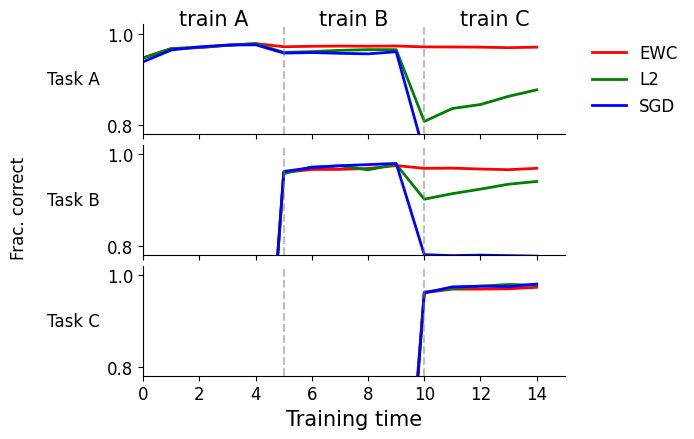

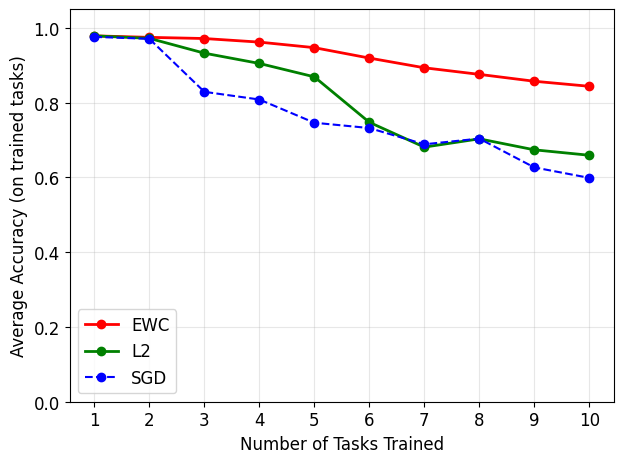

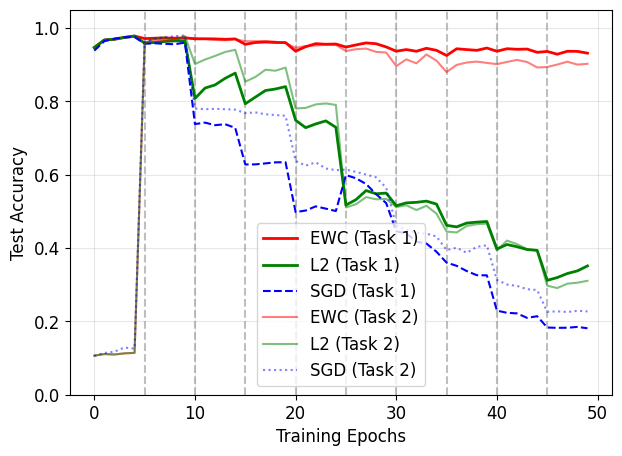

In [79]:
plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK, num_tasks, show_tasks=3)

### Experimental - trying out other parameters, epochs

In [ ]:
# Configuration
EPOCHS_PER_TASK = 5  # 5 epochs is sufficient for MNIST convergence
LAMBDA_EWC = 400
LAMBDA_L2 = 0.001
LR = 0.1


In [97]:
# 1. Run EWC
print("Running EWC...")
model_ewc = MLP().to(device)
hist_ewc = train_and_evaluate(model_ewc, tasks, device, method='ewc', epochs=EPOCHS_PER_TASK, lambda_ewc=LAMBDA_EWC, lr=LR)


# 2. Run SGD (No penalty)
print("\nRunning SGD (Catastrophic Forgetting)...")
model_sgd = MLP().to(device)
hist_sgd = train_and_evaluate(model_sgd, tasks, device, method='sgd', epochs=EPOCHS_PER_TASK, lr=LR)

# 3. Run L2 Regularization
print("\nRunning L2 Regularization...")
model_l2 = MLP().to(device)
hist_l2 = train_and_evaluate(model_l2, tasks, device, method='l2', epochs=EPOCHS_PER_TASK, lambda_l2=LAMBDA_L2, lr=LR)



Running EWC...

--- Training on Task 1 ---
Epoch 1/15 | Task 1 Acc: 0.9478
Epoch 2/15 | Task 1 Acc: 0.9636
Epoch 3/15 | Task 1 Acc: 0.9731
Epoch 4/15 | Task 1 Acc: 0.9759
Epoch 5/15 | Task 1 Acc: 0.9787
Epoch 6/15 | Task 1 Acc: 0.9768
Epoch 7/15 | Task 1 Acc: 0.9807
Epoch 8/15 | Task 1 Acc: 0.9778
Epoch 9/15 | Task 1 Acc: 0.9714
Epoch 10/15 | Task 1 Acc: 0.9824
Epoch 11/15 | Task 1 Acc: 0.9809
Epoch 12/15 | Task 1 Acc: 0.9824
Epoch 13/15 | Task 1 Acc: 0.9818
Epoch 14/15 | Task 1 Acc: 0.9821
Epoch 15/15 | Task 1 Acc: 0.9818
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/15 | Task 2 Acc: 0.9607
Epoch 2/15 | Task 2 Acc: 0.9692
Epoch 3/15 | Task 2 Acc: 0.9662
Epoch 4/15 | Task 2 Acc: 0.9739
Epoch 5/15 | Task 2 Acc: 0.9757
Epoch 6/15 | Task 2 Acc: 0.9722
Epoch 7/15 | Task 2 Acc: 0.9792
Epoch 8/15 | Task 2 Acc: 0.9775
Epoch 9/15 | Task 2 Acc: 0.9786
Epoch 10/15 | Task 2 Acc: 0.9773
Epoch 11/15 | Task 2 Acc: 0.9794
Epoch 12/15 | Task 2 Acc: 0.9789
Epoch 13/15 | Tas

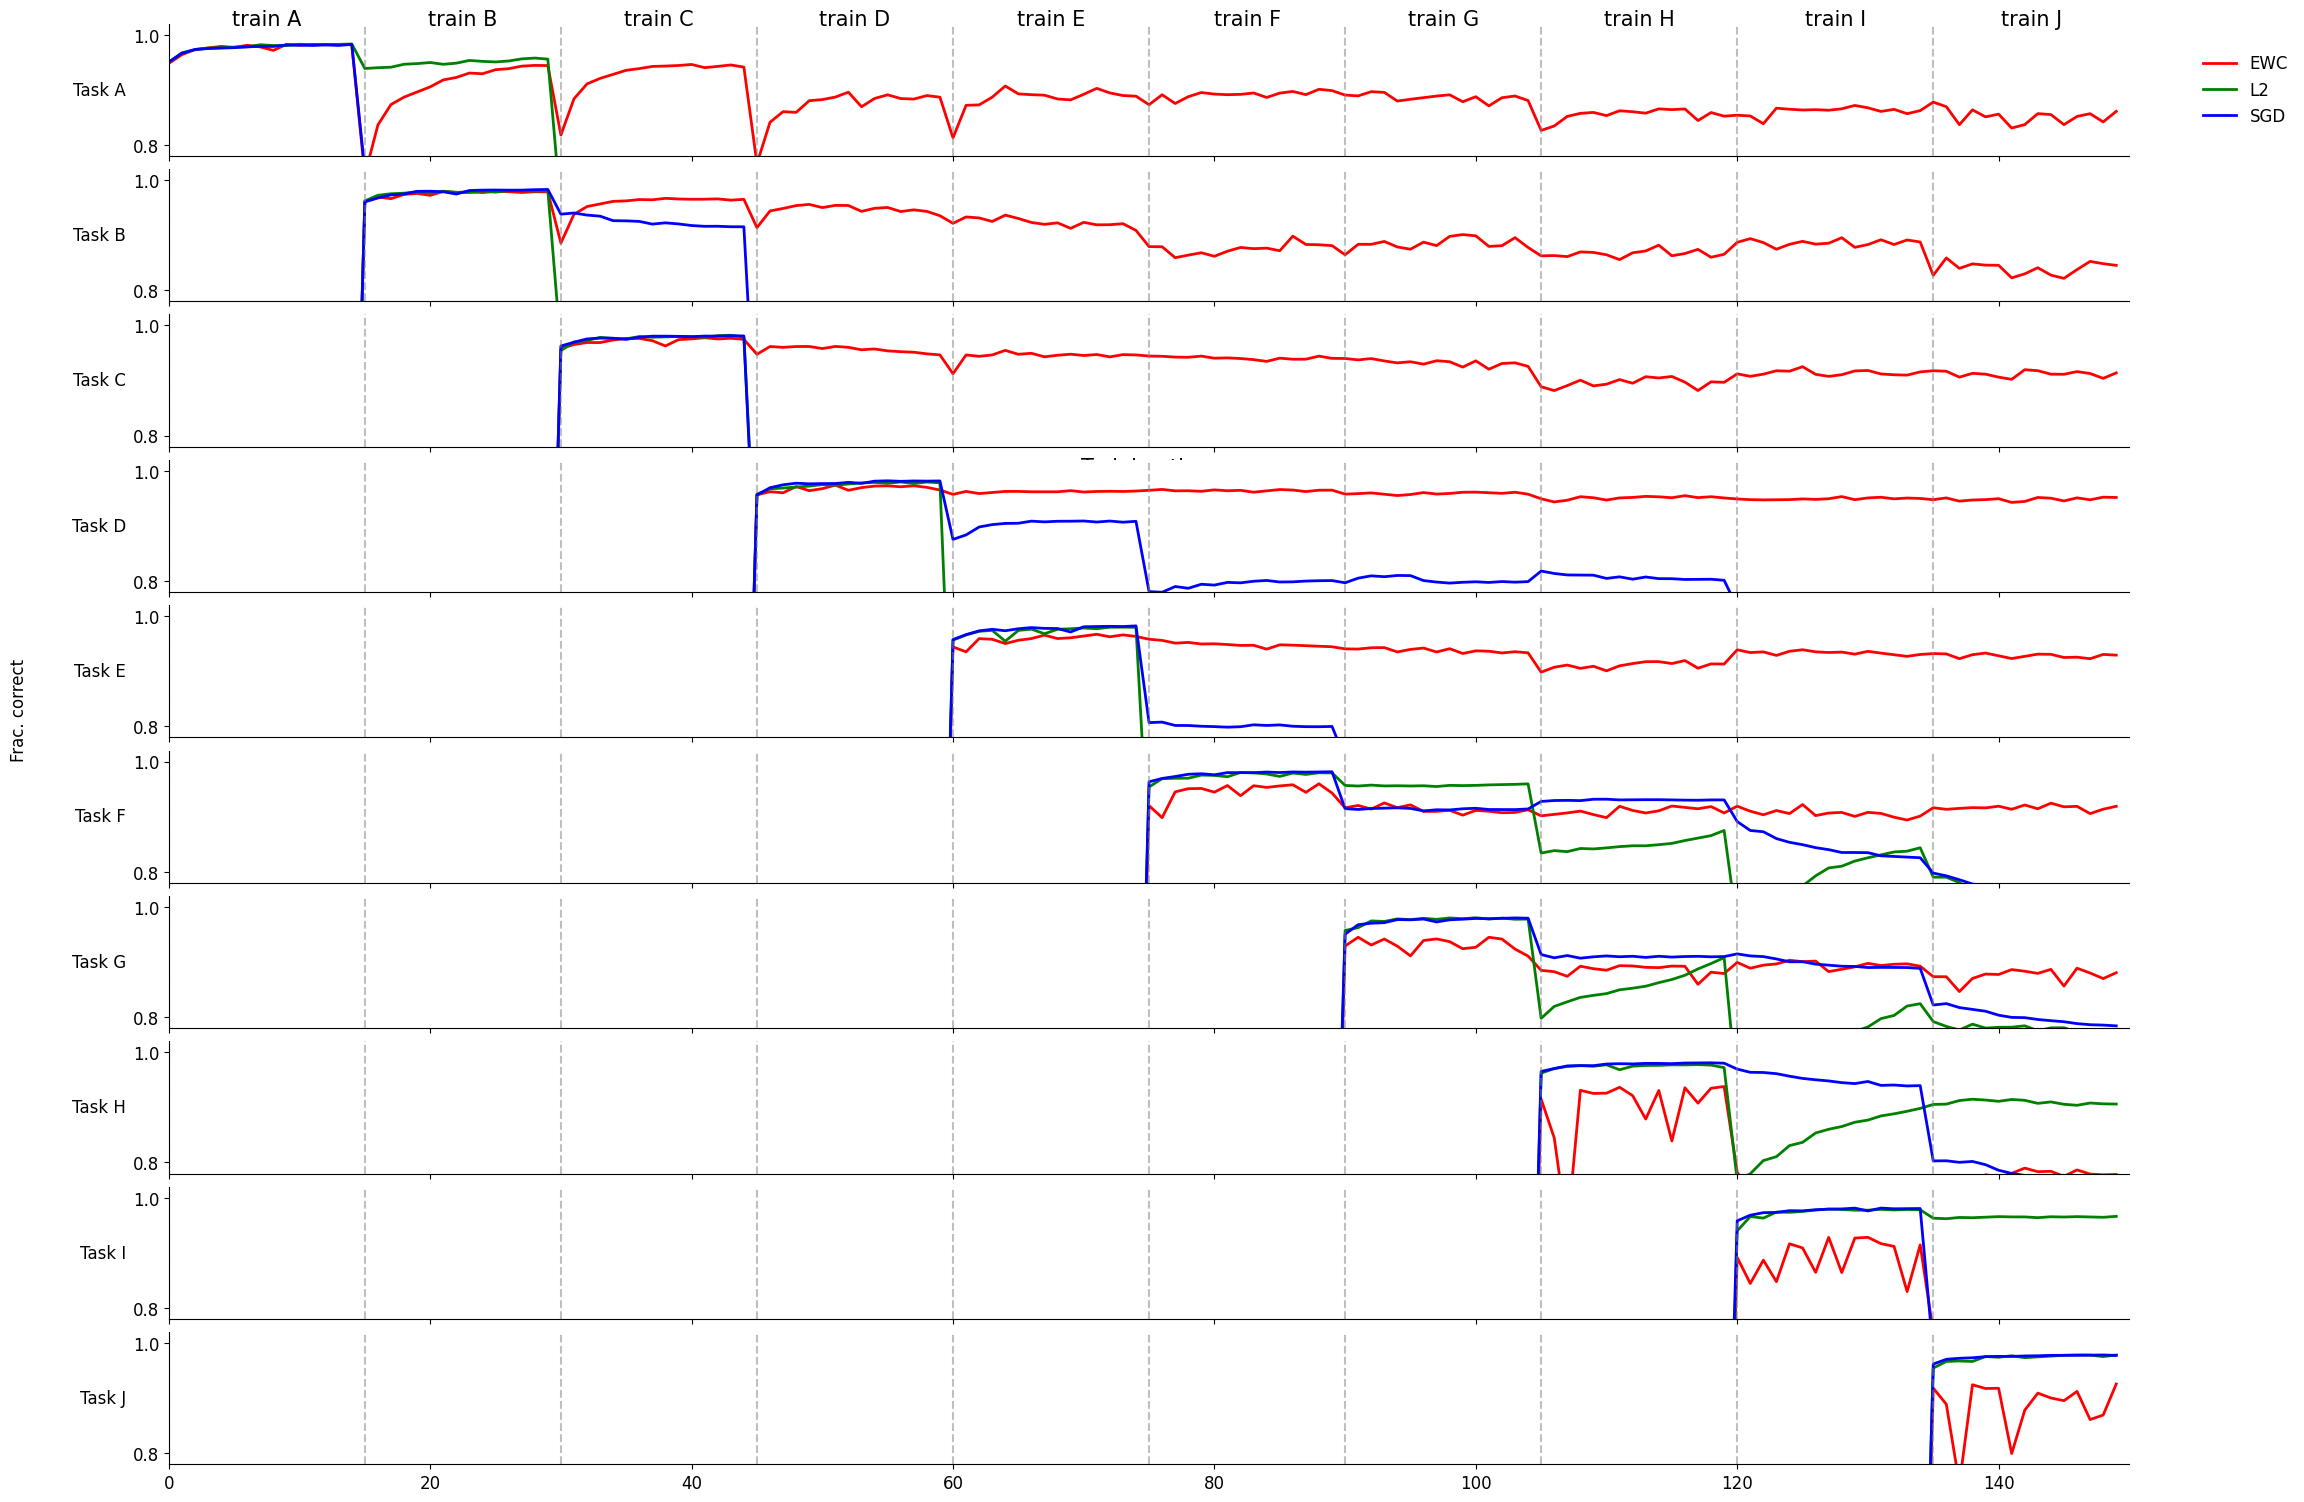

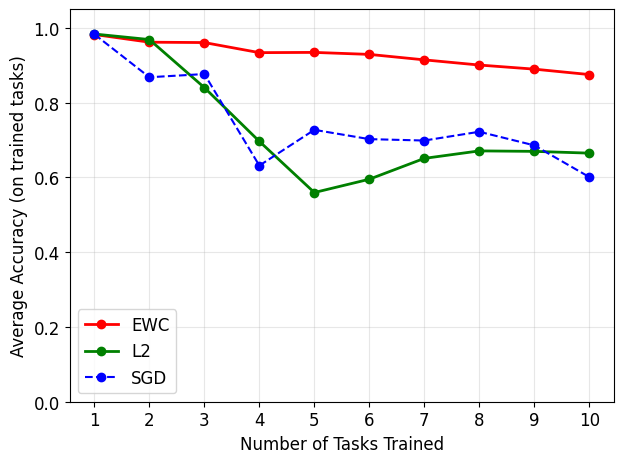

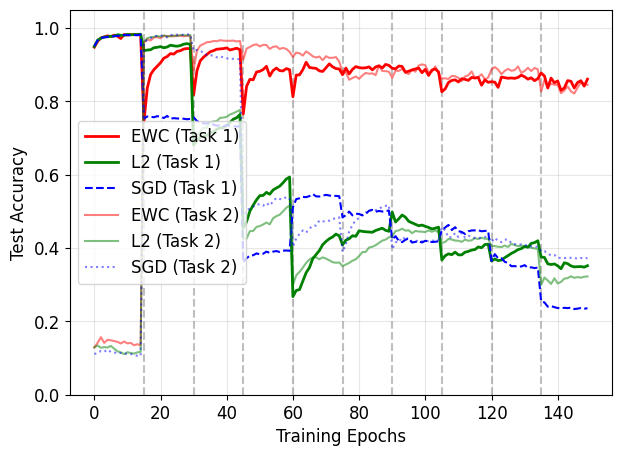

In [98]:
plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK, num_tasks, show_tasks=10)

In [ ]:
# changing normalization  v3 + changing the nb of samples in fischer from 500 -> 2000 

class EWC:
    def __init__(self, model: nn.Module, lambda_ewc: float = 2000):
        self.model = model
        self.lambda_ewc = lambda_ewc
        self.tasks = [] # Stores (params, fisher) tuples for each previous task

    def register_task(self, train_loader, device):
        """
        Called after finishing a task. Computes and stores the Fisher Matrix
        and current parameters.
        """
        params = {n: p.data.clone().cpu() for n, p in self.model.named_parameters()}
        fisher = fisher_matrix_diag(self.model, train_loader, device)
        # Move fisher to CPU to save GPU memory
        fisher = {n: f.cpu() for n, f in fisher.items()}
        self.tasks.append((params, fisher))
        print(f"Task registered. Total stored tasks: {len(self.tasks)}")

    def penalty(self, device):
        """
        Calculates the EWC loss penalty by summing over all previous tasks.
        """
        loss = 0
        for params_old, fisher_old in self.tasks:
            for n, p in self.model.named_parameters():
                # Move stored tensors to device for calculation
                f = fisher_old[n].to(device)
                p_old = params_old[n].to(device)

                # Loss = sum( F * (current - old)^2 )
                loss += (f * (p - p_old) ** 2).sum()

        return (self.lambda_ewc / 2) * loss  # No division by len(self.tasks)
        


In [100]:
# Configuration
EPOCHS_PER_TASK = 5  # 5 epochs is sufficient for MNIST convergence
LAMBDA_EWC = 200
LAMBDA_L2 = 0.001
LR = 0.1


Running EWC...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9439
Epoch 2/5 | Task 1 Acc: 0.9588
Epoch 3/5 | Task 1 Acc: 0.9706
Epoch 4/5 | Task 1 Acc: 0.9770
Epoch 5/5 | Task 1 Acc: 0.9766
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9565
Epoch 2/5 | Task 2 Acc: 0.9408
Epoch 3/5 | Task 2 Acc: 0.9670
Epoch 4/5 | Task 2 Acc: 0.9727
Epoch 5/5 | Task 2 Acc: 0.9715
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9384
Epoch 2/5 | Task 3 Acc: 0.9558
Epoch 3/5 | Task 3 Acc: 0.9477
Epoch 4/5 | Task 3 Acc: 0.9627
Epoch 5/5 | Task 3 Acc: 0.9659
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9084
Epoch 2/5 | Task 4 Acc: 0.9418
Epoch 3/5 | Task 4 Acc: 0.9441
Epoch 4/5 | Task 4 Acc: 0.9378
Epoch 5/5 | Task 4 Acc: 0.9367
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9116
Epoch 2/5 | Task 5 Acc: 0.9255
Epoch 3

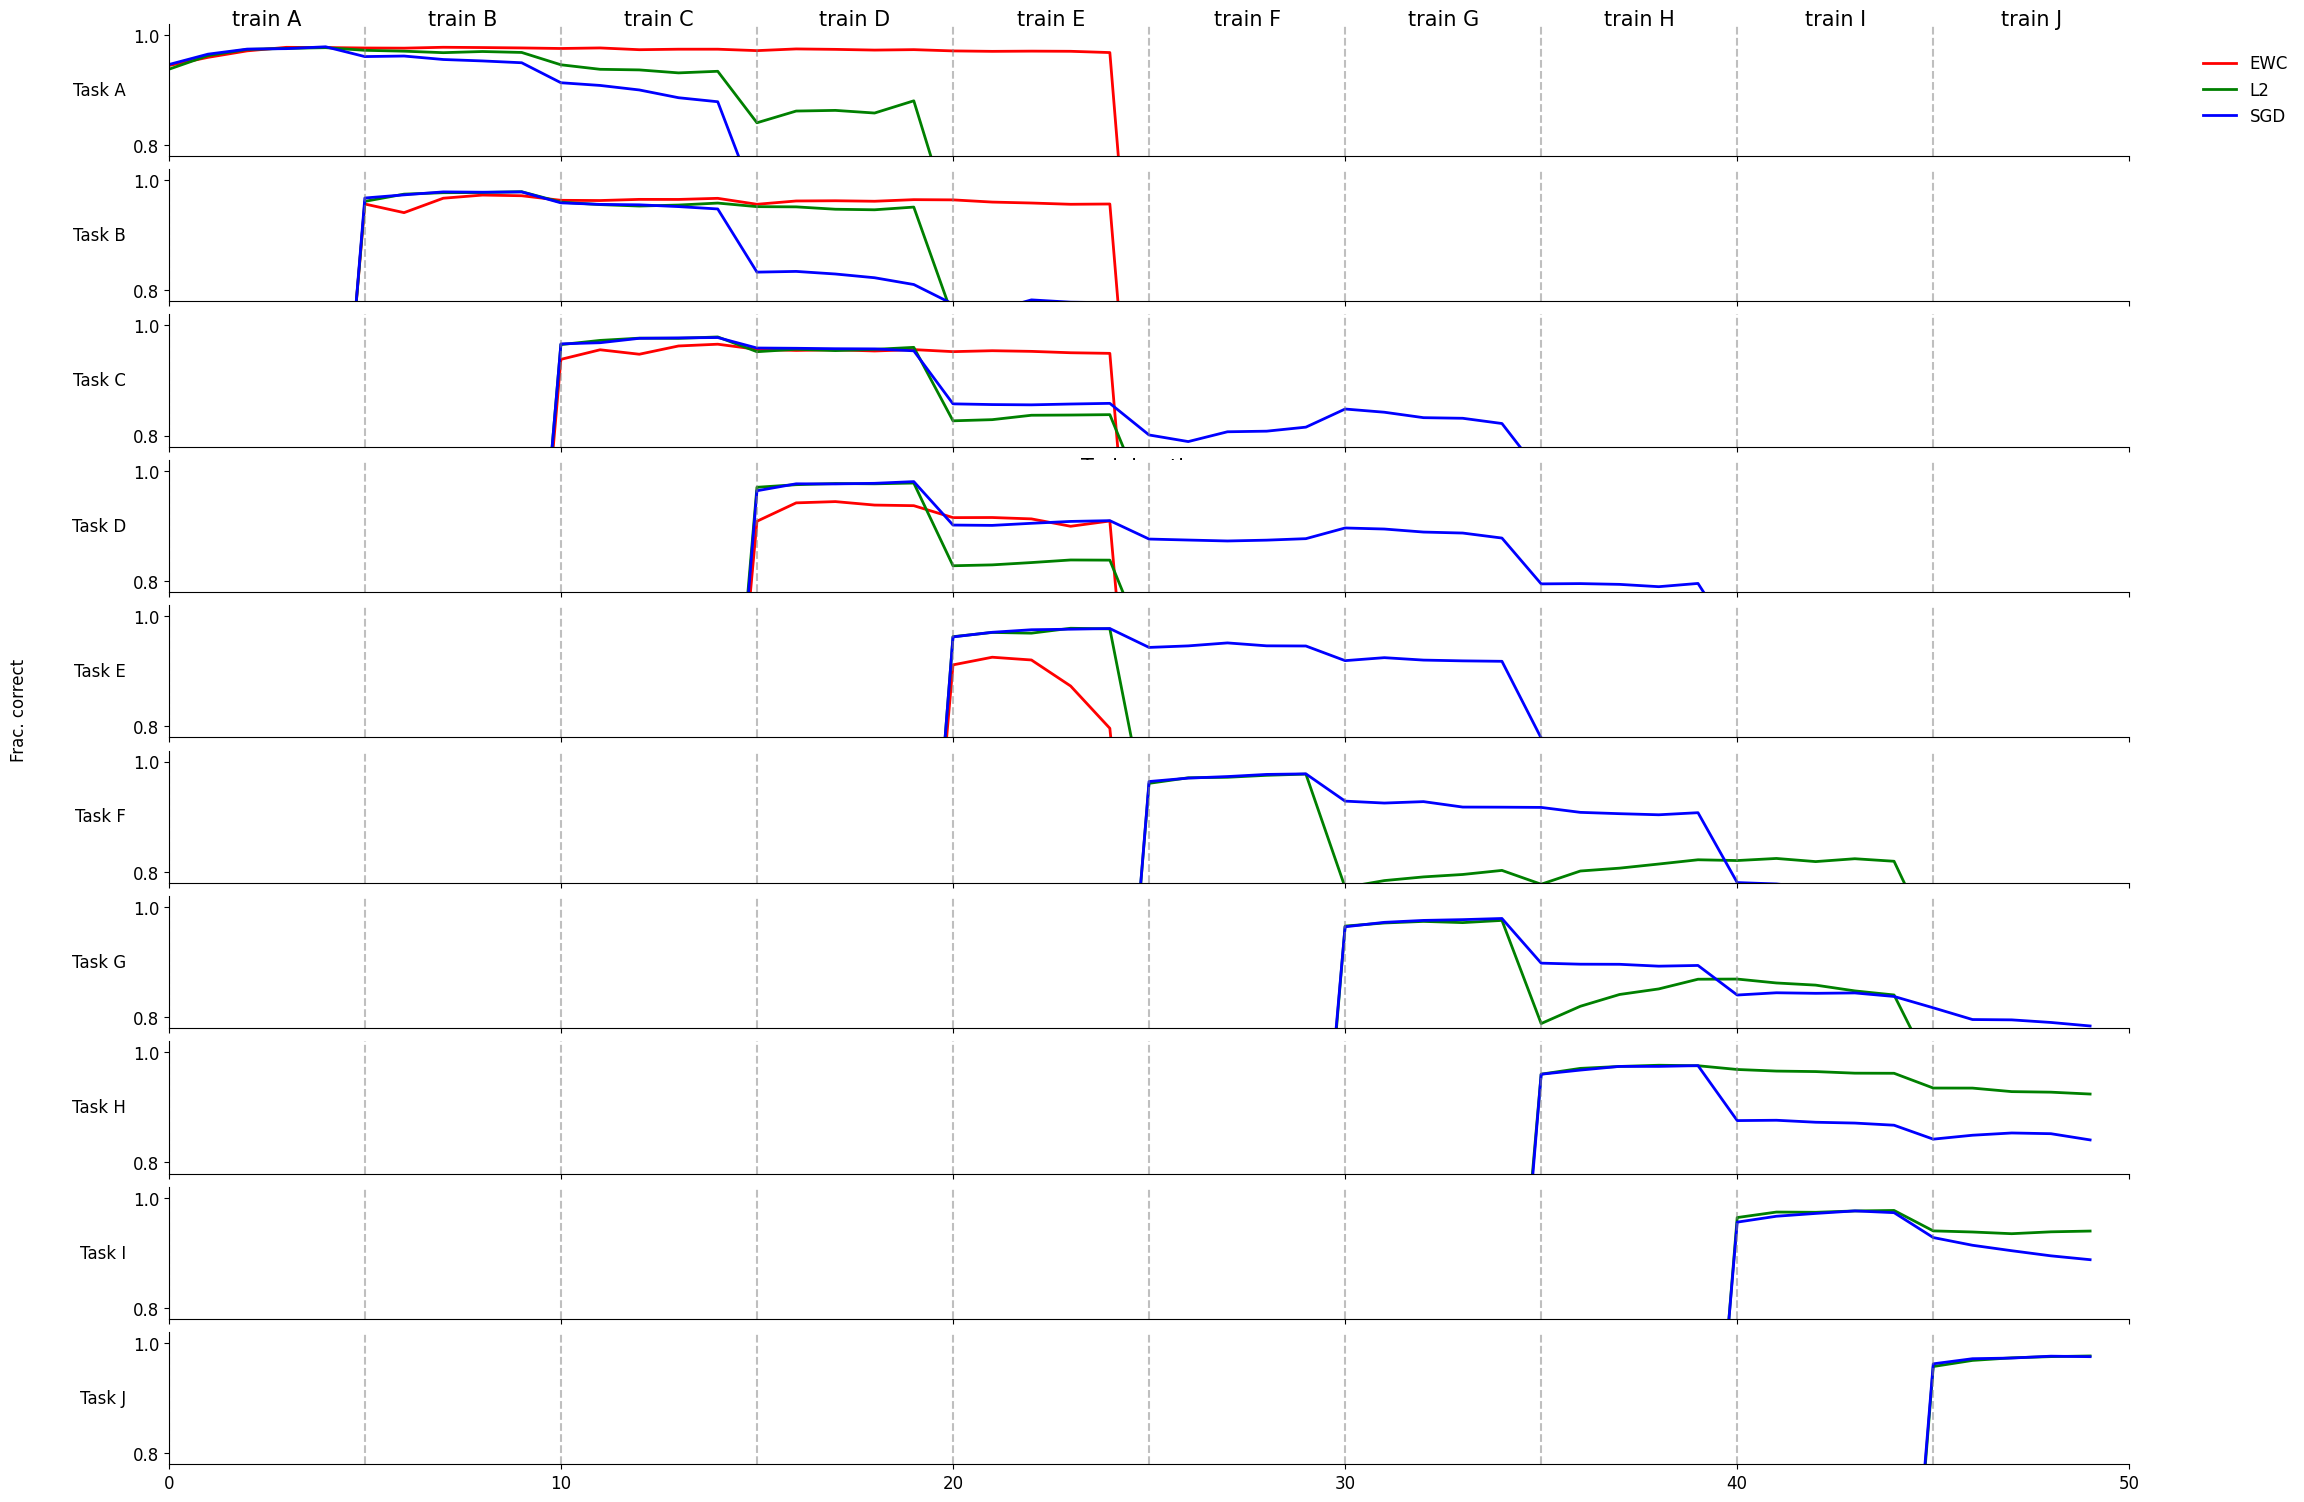

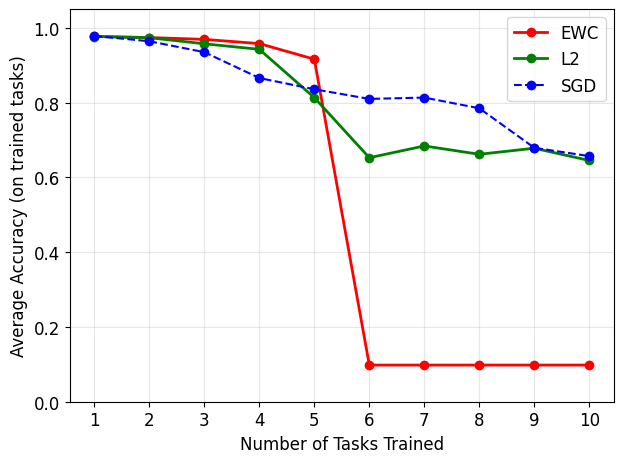

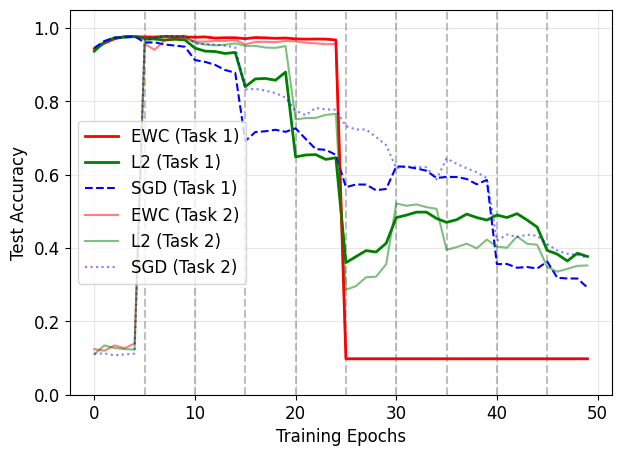

In [101]:
# 1. Run EWC
print("Running EWC...")
model_ewc = MLP().to(device)
hist_ewc = train_and_evaluate(model_ewc, tasks, device, method='ewc', epochs=EPOCHS_PER_TASK, lambda_ewc=LAMBDA_EWC, lr=LR)


# 2. Run SGD (No penalty)
print("\nRunning SGD (Catastrophic Forgetting)...")
model_sgd = MLP().to(device)
hist_sgd = train_and_evaluate(model_sgd, tasks, device, method='sgd', epochs=EPOCHS_PER_TASK, lr=LR)

# 3. Run L2 Regularization
print("\nRunning L2 Regularization...")
model_l2 = MLP().to(device)
hist_l2 = train_and_evaluate(model_l2, tasks, device, method='l2', epochs=EPOCHS_PER_TASK, lambda_l2=LAMBDA_L2, lr=LR)


plot_results(hist_ewc, hist_l2, hist_sgd, EPOCHS_PER_TASK, num_tasks, show_tasks=10)


### Figure 2A and 2B: RotatedMNIST Results

In [ ]:
def train_and_evaluate_rotated(model, tasks, device, method="ewc", epochs=5, ewc_lambda=10, l2_lambda=10, lr=0.01):
    return train_and_evaluate(
        model,
        tasks,
        device,
        method=method,
        epochs=epochs,
        lambda_ewc=ewc_lambda,
        lambda_l2=l2_lambda,
        lr=lr,
    )


In [14]:
# Params
EWC_LAMBDA = 100
L2_LAMBDA = 1e-4
ROTATED_LR = 0.1
ROTATED_BATCH = 128
ROTATED_ANGLE_STEP = 10
EPOCHS_PER_TASK = 5  

# Generate rotated tasks (10 tasks, 0..90 degrees)
num_tasks=10
rotated_tasks = get_rotated_mnist_tasks(num_tasks=10, batch_size=ROTATED_BATCH, angle_step=ROTATED_ANGLE_STEP)


Generating Task 1 (Rotation 0°)...
Generating Task 2 (Rotation 10°)...
Generating Task 3 (Rotation 20°)...
Generating Task 4 (Rotation 30°)...
Generating Task 5 (Rotation 40°)...
Generating Task 6 (Rotation 50°)...
Generating Task 7 (Rotation 60°)...
Generating Task 8 (Rotation 70°)...
Generating Task 9 (Rotation 80°)...
Generating Task 10 (Rotation 90°)...


In [15]:
# Run EWC training
model_ewc_rot = MLP().to(device)
hist_ewc_rot = train_and_evaluate_rotated(model_ewc_rot, rotated_tasks, device, method="ewc", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)



--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9474
Epoch 2/5 | Task 1 Acc: 0.9647
Epoch 3/5 | Task 1 Acc: 0.9695
Epoch 4/5 | Task 1 Acc: 0.9750
Epoch 5/5 | Task 1 Acc: 0.9749
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9710
Epoch 2/5 | Task 2 Acc: 0.9762
Epoch 3/5 | Task 2 Acc: 0.9741
Epoch 4/5 | Task 2 Acc: 0.9764
Epoch 5/5 | Task 2 Acc: 0.9765
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9720
Epoch 2/5 | Task 3 Acc: 0.9762
Epoch 3/5 | Task 3 Acc: 0.9714
Epoch 4/5 | Task 3 Acc: 0.9744
Epoch 5/5 | Task 3 Acc: 0.9715
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9734
Epoch 2/5 | Task 4 Acc: 0.9732
Epoch 3/5 | Task 4 Acc: 0.9754
Epoch 4/5 | Task 4 Acc: 0.9735
Epoch 5/5 | Task 4 Acc: 0.9744
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9711
Epoch 2/5 | Task 5 Acc: 0.9697
Epoch 3/5 | Task 5 Acc

In [16]:

# Run other training

print("\nRunning SGD (Catastrophic Forgetting) on RotatedMNIST...")
model_sgd_rot = MLP().to(device)
hist_sgd_rot = train_and_evaluate_rotated(model_sgd_rot, rotated_tasks, device, method="sgd", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)

print("\nRunning L2 Regularization on RotatedMNIST...")
model_l2_rot = MLP().to(device)
hist_l2_rot = train_and_evaluate_rotated(model_l2_rot, rotated_tasks, device, method="l2", epochs=EPOCHS_PER_TASK, ewc_lambda=EWC_LAMBDA, l2_lambda=L2_LAMBDA, lr=ROTATED_LR)



Running SGD (Catastrophic Forgetting) on RotatedMNIST...

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9494
Epoch 2/5 | Task 1 Acc: 0.9642
Epoch 3/5 | Task 1 Acc: 0.9700
Epoch 4/5 | Task 1 Acc: 0.9764
Epoch 5/5 | Task 1 Acc: 0.9765

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9756
Epoch 2/5 | Task 2 Acc: 0.9783
Epoch 3/5 | Task 2 Acc: 0.9814
Epoch 4/5 | Task 2 Acc: 0.9799
Epoch 5/5 | Task 2 Acc: 0.9822

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9775
Epoch 2/5 | Task 3 Acc: 0.9819
Epoch 3/5 | Task 3 Acc: 0.9810
Epoch 4/5 | Task 3 Acc: 0.9792
Epoch 5/5 | Task 3 Acc: 0.9819

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9784
Epoch 2/5 | Task 4 Acc: 0.9790
Epoch 3/5 | Task 4 Acc: 0.9758
Epoch 4/5 | Task 4 Acc: 0.9822
Epoch 5/5 | Task 4 Acc: 0.9812

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9767
Epoch 2/5 | Task 5 Acc: 0.9784
Epoch 3/5 | Task 5 Acc: 0.9824
Epoch 4/5 | Task 5 Acc: 0.9820
Epoch 5/5 | Task 5 Acc: 0.9838

--- Training on Task 6 ---

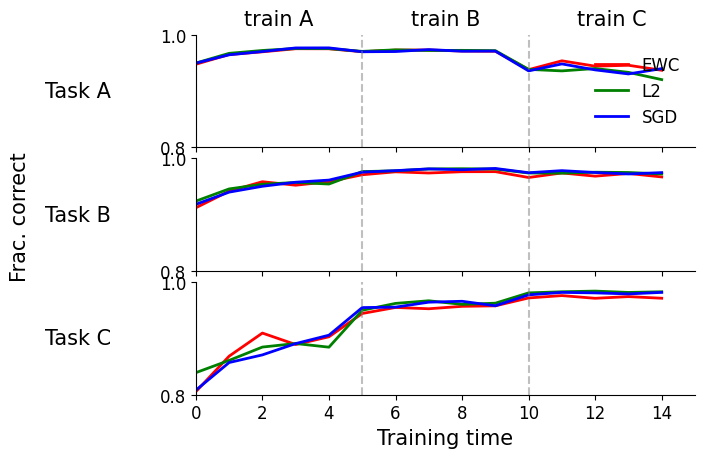

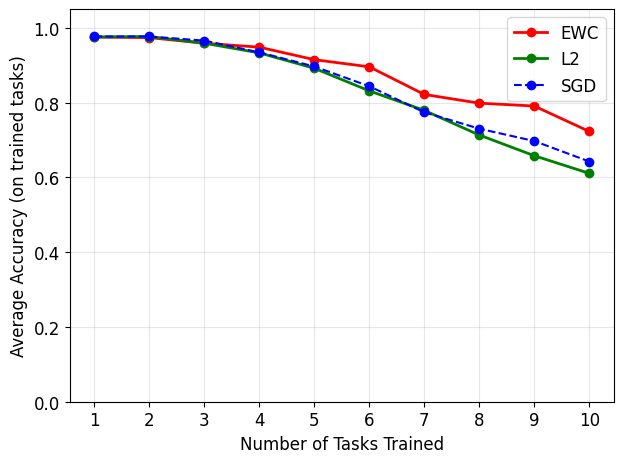

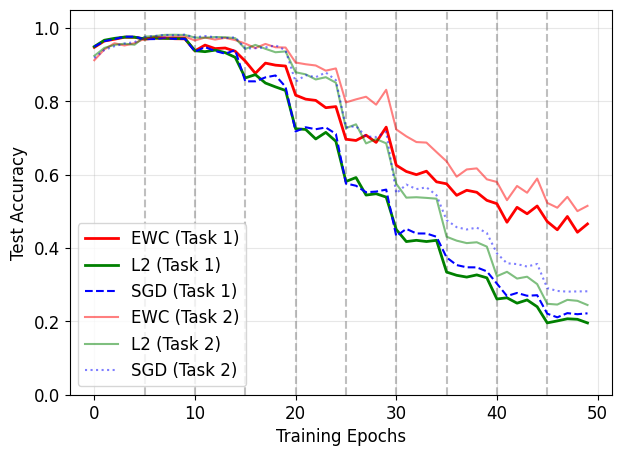

In [17]:
plot_results(hist_ewc_rot, hist_l2_rot, hist_sgd_rot, EPOCHS_PER_TASK, num_tasks)

Starting EWC Grid Search...

Testing λ=50, lr=0.05

--- Training on Task 1 ---
Epoch 1/5 | Task 1 Acc: 0.9469
Epoch 2/5 | Task 1 Acc: 0.9674
Epoch 3/5 | Task 1 Acc: 0.9695
Epoch 4/5 | Task 1 Acc: 0.9745
Epoch 5/5 | Task 1 Acc: 0.9782
Task registered. Total stored tasks: 1

--- Training on Task 2 ---
Epoch 1/5 | Task 2 Acc: 0.9628
Epoch 2/5 | Task 2 Acc: 0.9712
Epoch 3/5 | Task 2 Acc: 0.9713
Epoch 4/5 | Task 2 Acc: 0.9717
Epoch 5/5 | Task 2 Acc: 0.9771
Task registered. Total stored tasks: 2

--- Training on Task 3 ---
Epoch 1/5 | Task 3 Acc: 0.9645
Epoch 2/5 | Task 3 Acc: 0.9716
Epoch 3/5 | Task 3 Acc: 0.9716
Epoch 4/5 | Task 3 Acc: 0.9760
Epoch 5/5 | Task 3 Acc: 0.9779
Task registered. Total stored tasks: 3

--- Training on Task 4 ---
Epoch 1/5 | Task 4 Acc: 0.9615
Epoch 2/5 | Task 4 Acc: 0.9642
Epoch 3/5 | Task 4 Acc: 0.9724
Epoch 4/5 | Task 4 Acc: 0.9767
Epoch 5/5 | Task 4 Acc: 0.9788
Task registered. Total stored tasks: 4

--- Training on Task 5 ---
Epoch 1/5 | Task 5 Acc: 0.9562
Ep

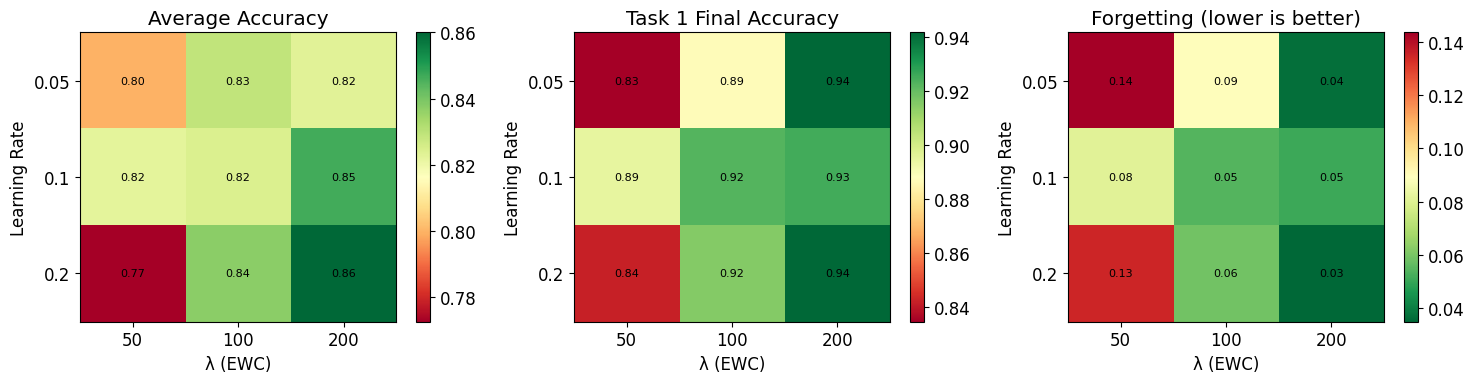

In [16]:
# Cell - EWC Grid Search
import torch
import numpy as np

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Generate tasks once
num_tasks = 10
tasks = get_permuted_mnist_tasks(num_tasks)
EPOCHS_PER_TASK = 5

# Define search space
ewc_lambdas = [50, 100, 200]  # Fewer values
learning_rates = [0.05, 0.1, 0.2]  # Fewer values

results = []

print("Starting EWC Grid Search...")
print("="*60)

for lam in ewc_lambdas:
    for lr in learning_rates:
        print(f"\nTesting λ={lam}, lr={lr}")
        
        # Train with these hyperparameters
        model = MLP().to(device)
        hist = train_and_evaluate(model, tasks, device, method='ewc',
                                  epochs=EPOCHS_PER_TASK,
                                  lambda_ewc=lam,
                                  lr=lr)
        
        # Calculate final average accuracy across all tasks
        final_avg = np.mean([hist[i][-1] for i in range(num_tasks)])
        
        # Also calculate forgetting (Task 1 accuracy drop)
        task1_initial = hist[0][EPOCHS_PER_TASK - 1]  # After training task 1
        task1_final = hist[0][-1]  # After all tasks
        forgetting = task1_initial - task1_final
        
        results.append({
            'lambda': lam,
            'lr': lr,
            'avg_acc': final_avg,
            'task1_final': task1_final,
            'forgetting': forgetting
        })
        
        print(f"  Avg Acc: {final_avg:.3f} | Task 1 Final: {task1_final:.3f} | Forgetting: {forgetting:.3f}")

# Find best configuration
best_avg = max(results, key=lambda x: x['avg_acc'])
best_task1 = max(results, key=lambda x: x['task1_final'])
best_forgetting = min(results, key=lambda x: x['forgetting'])

print("\n" + "="*60)
print("BEST CONFIGURATIONS:")
print("="*60)
print(f"Best Avg Accuracy: λ={best_avg['lambda']}, lr={best_avg['lr']:.2f} → {best_avg['avg_acc']:.3f}")
print(f"Best Task 1 Retention: λ={best_task1['lambda']}, lr={best_task1['lr']:.2f} → {best_task1['task1_final']:.3f}")
print(f"Least Forgetting: λ={best_forgetting['lambda']}, lr={best_forgetting['lr']:.2f} → {best_forgetting['forgetting']:.3f}")

# Visualize results
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Create matrix for heatmap
lambda_idx = {lam: i for i, lam in enumerate(ewc_lambdas)}
lr_idx = {lr: i for i, lr in enumerate(learning_rates)}

avg_matrix = np.zeros((len(learning_rates), len(ewc_lambdas)))
for r in results:
    avg_matrix[lr_idx[r['lr']], lambda_idx[r['lambda']]] = r['avg_acc']

# Heatmap 1: Average Accuracy
im1 = axes[0].imshow(avg_matrix, cmap='RdYlGn', aspect='auto')
axes[0].set_xticks(range(len(ewc_lambdas)))
axes[0].set_xticklabels(ewc_lambdas)
axes[0].set_yticks(range(len(learning_rates)))
axes[0].set_yticklabels(learning_rates)
axes[0].set_xlabel('λ (EWC)')
axes[0].set_ylabel('Learning Rate')
axes[0].set_title('Average Accuracy')
plt.colorbar(im1, ax=axes[0])

# Add values to heatmap
for i in range(len(learning_rates)):
    for j in range(len(ewc_lambdas)):
        axes[0].text(j, i, f'{avg_matrix[i,j]:.2f}', 
                    ha='center', va='center', color='black', fontsize=8)

# Heatmap 2: Task 1 Final Accuracy
task1_matrix = np.zeros((len(learning_rates), len(ewc_lambdas)))
for r in results:
    task1_matrix[lr_idx[r['lr']], lambda_idx[r['lambda']]] = r['task1_final']

im2 = axes[1].imshow(task1_matrix, cmap='RdYlGn', aspect='auto')
axes[1].set_xticks(range(len(ewc_lambdas)))
axes[1].set_xticklabels(ewc_lambdas)
axes[1].set_yticks(range(len(learning_rates)))
axes[1].set_yticklabels(learning_rates)
axes[1].set_xlabel('λ (EWC)')
axes[1].set_ylabel('Learning Rate')
axes[1].set_title('Task 1 Final Accuracy')
plt.colorbar(im2, ax=axes[1])

for i in range(len(learning_rates)):
    for j in range(len(ewc_lambdas)):
        axes[1].text(j, i, f'{task1_matrix[i,j]:.2f}', 
                    ha='center', va='center', color='black', fontsize=8)

# Heatmap 3: Forgetting
forget_matrix = np.zeros((len(learning_rates), len(ewc_lambdas)))
for r in results:
    forget_matrix[lr_idx[r['lr']], lambda_idx[r['lambda']]] = r['forgetting']

im3 = axes[2].imshow(forget_matrix, cmap='RdYlGn_r', aspect='auto')  # Reversed colormap (less is better)
axes[2].set_xticks(range(len(ewc_lambdas)))
axes[2].set_xticklabels(ewc_lambdas)
axes[2].set_yticks(range(len(learning_rates)))
axes[2].set_yticklabels(learning_rates)
axes[2].set_xlabel('λ (EWC)')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('Forgetting (lower is better)')
plt.colorbar(im3, ax=axes[2])

for i in range(len(learning_rates)):
    for j in range(len(ewc_lambdas)):
        axes[2].text(j, i, f'{forget_matrix[i,j]:.2f}', 
                    ha='center', va='center', color='black', fontsize=8)

plt.tight_layout()
plt.show()